In [8]:
from dask.distributed import Client
# client = Client(memory_limit = '15GB', threads_per_worker = 4)
client = Client(threads_per_worker = 4)
# client = Client(memory_limit = '8GB')
client.upload_file('/g/data/vf71/la6889/dbpm_fishmip2300_runs/scripts/useful_functions.py')
# client.amm.start()

{'tcp://127.0.0.1:42195': {'status': 'OK'},
 'tcp://127.0.0.1:42315': {'status': 'OK'},
 'tcp://127.0.0.1:46653': {'status': 'OK'}}

In [22]:
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/41893/status,
Dashboard: /proxy/41893/status,Workers: 14
Total threads: 14,Total memory: 63.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:35645,Workers: 0
Dashboard: /proxy/41893/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:39347,Total threads: 1
Dashboard: /proxy/38309/status,Memory: 4.50 GiB
Nanny: tcp://127.0.0.1:42715,


In [3]:
import os
os.chdir('/g/data/vf71/la6889/dbpm_fishmip2300_runs/scripts/')
import numpy as np
from glob import glob
import pandas as pd
import re
import useful_functions as uf
import pandas as pd
import xarray as xr
import dask
from pathlib import Path

In [17]:
bio_files = Path('/g/data/vf71/fishmip_outputs/ISIMIP3a/global').rglob('*[soc|nat]_[def|60a]*[min|ult]_tcb_*')

In [21]:
bio_files = Path('/g/data/vf71/fishmip_outputs/ISIMIP3a/global').rglob('*[soc|nat]_[def|60a]*[min|ult]_[bd|bp]*')

TypeError: unsupported operand type(s) for +=: 'generator' and 'generator'

In [15]:
catch_files = Path('/g/data/vf71/fishmip_outputs/ISIMIP3a/global').rglob('*[soc|nat]_[def|60a]*[min|ult]_tc_*')

In [20]:
[p for p in test]

[PosixPath('/g/data/vf71/fishmip_outputs/ISIMIP3a/global/EcoOcean/gfdl-mom6-cobalt2/ecoocean_gfdl-mom6-cobalt2_obsclim_histsoc_60arcmin_bd30to90cm_global_monthly_1961_2010.nc'),
 PosixPath('/g/data/vf71/fishmip_outputs/ISIMIP3a/global/EcoOcean/gfdl-mom6-cobalt2/ecoocean_gfdl-mom6-cobalt2_obsclim_histsoc_60arcmin_bp30cm_global_monthly_1961_2010.nc'),
 PosixPath('/g/data/vf71/fishmip_outputs/ISIMIP3a/global/EcoOcean/gfdl-mom6-cobalt2/ecoocean_gfdl-mom6-cobalt2_obsclim_histsoc_60arcmin_bd90cm_global_monthly_1961_2010.nc'),
 PosixPath('/g/data/vf71/fishmip_outputs/ISIMIP3a/global/EcoOcean/gfdl-mom6-cobalt2/ecoocean_gfdl-mom6-cobalt2_obsclim_nat_60arcmin_bp30cm_global_monthly_1961_2010.nc'),
 PosixPath('/g/data/vf71/fishmip_outputs/ISIMIP3a/global/EcoOcean/gfdl-mom6-cobalt2/ecoocean_gfdl-mom6-cobalt2_obsclim_histsoc_60arcmin_bp90cm_global_monthly_1961_2010.nc'),
 PosixPath('/g/data/vf71/fishmip_outputs/ISIMIP3a/global/EcoOcean/gfdl-mom6-cobalt2/ecoocean_gfdl-mom6-cobalt2_obsclim_histsoc_60a

In [2]:
base_dir = '/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/'

In [3]:
esm_names = os.listdir(os.path.join(base_dir, 'picontrol'))
esm_names

['CESM2-WACCM', 'IPSL-CM6A-LR', 'UKESM1-0-LL']

In [4]:
# List all folders for a given ESM
exp_names = os.listdir(base_dir)
exp_names

['ssp126', 'ssp370', 'historical', 'ssp585', 'picontrol']

In [5]:
# Get weights
[weight_file] = glob(os.path.join(base_dir, f'*/{esm_names[1]}/*_bio-weights_*'))
weight_file

'/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/picontrol/IPSL-CM6A-LR/ipsl-cm6a-lr_r1i1p1f1_picontrol_bio-weights_60arcmin_global_monthly_1961_1980.zarr'

In [6]:
folder_gridded_data = os.path.join(base_dir, exp_names[0], esm_names[1])
folder_gridded_data

'/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/ssp126/IPSL-CM6A-LR'

In [7]:
phyc, phyto, temp = uf.integrating_inputs(folder_gridded_data, esm_exp = esm_names[0], thresh_depth = 200, 
                                          averaging = 'custom', phyto_group = 'phydiat', weights = weight_file)

ValueError: 'lev' not found in array dimensions ('time', 'olevel', 'lat', 'lon')

In [10]:
[depth_fn] = glob(os.path.join(folder_gridded_data, '*_thkcello_*'))
depth_fn

'/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/ssp126/IPSL-CM6A-LR/ipsl-cm6a-lr_r1i1p1f1_ssp126_thkcello_60arcmin_global_monthly_2015_2100.zarr'

In [19]:
glob(os.path.join(folder_gridded_data, '*_thetao_*'))

['/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/ssp126/IPSL-CM6A-LR/ipsl-cm6a-lr_r1i1p1f1_ssp126_thetao_60arcmin_global_monthly_2015_2100.zarr']

In [15]:
depth_bins = xr.open_zarr(depth_fn, decode_times = False)['thkcello']#.fillna(0)
depth_bins

<xarray.DataArray 'thkcello' (time: 1032, olevel: 75, lat: 180, lon: 360)> Size: 20GB
dask.array<open_dataset-thkcello, shape=(1032, 75, 180, 360), dtype=float32, chunksize=(38, 75, 180, 360), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) float64 8kB 4.968e+03 4.969e+03 4.97e+03 ... 5.998e+03 6e+03
  * olevel   (olevel) float32 300B 0.5058 1.556 2.668 ... 5.698e+03 5.902e+03
  * lat      (lat) float64 1kB 89.5 88.5 87.5 86.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
Attributes:
    standard_name:       cell_thickness
    long_name:           Ocean Model Cell Thickness
    units:               m
    online_operation:    average
    cell_methods:        area: mean where sea time: mean
    interval_operation:  2700 s
    interval_write:      1 month
    cell_measures:       area: areacello volume: volcello
    description:         "Thickness" means the vertical extent of a layer. "C...
    history:             none

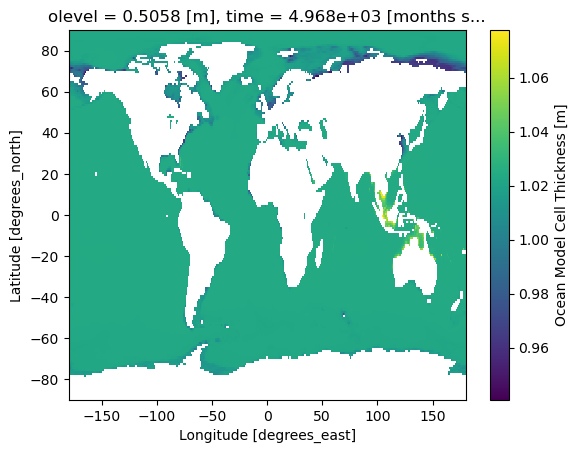

In [16]:
depth_bins.isel(time = 0, olevel = 0).plot()

In [8]:
depth_bins = (xr.open_zarr(glob(
            os.path.join(folder_gridded_data, f'*_thkcello_*'))[0])['thkcello'].
            drop_vars('time').squeeze().fillna(0))

ValueError: unable to decode time units 'months since 1601-1-1 00:00:00' with "calendar 'gregorian'". Try opening your dataset with decode_times=False or installing cftime if it is not installed.

In [ ]:
esm_folders = glob(os.path.join(base_dir, '*', esm_names[1]))
esm_folders

In [34]:
exp_esm_folder = glob(os.path.join(base_dir, f'*/{esm_names[1]}'))
exp_esm_folder

['/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/ssp126/IPSL-CM6A-LR',
 '/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/ssp370/IPSL-CM6A-LR',
 '/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/historical/IPSL-CM6A-LR',
 '/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/ssp585/IPSL-CM6A-LR',
 '/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/picontrol/IPSL-CM6A-LR']

In [30]:
[f for f in weight_files if esm_names[0] in f]

[]

In [8]:
glob(os.path.join(base_dir, 'picontrol/*/*'))

['/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/picontrol/IPSL-CM6A-LR/ipsl-cm6a-lr_r1i1p1f1_picontrol_thkcello_60arcmin_global_monthly_1650_1849.zarr',
 '/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/picontrol/IPSL-CM6A-LR/ipsl-cm6a-lr_r1i1p1f1_picontrol_phydiat_60arcmin_global_monthly_1650_1849.zarr',
 '/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/picontrol/IPSL-CM6A-LR/ipsl-cm6a-lr_r1i1p1f1_picontrol_expc-bot_60arcmin_global_monthly_1650_1849.zarr',
 '/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/picontrol/IPSL-CM6A-LR/ipsl-cm6a-lr_r1i1p1f1_picontrol_thetao_60arcmin_global_monthly_1650_1849.zarr',
 '/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/picontrol/IPSL-CM6A-LR/ipsl-cm6a-lr_r1i1p1f1_picontrol_input-w20m_60arcmin_global_monthly_1650_1849.zarr',
 '/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/picontrol/IPSL-CM6A-LR/ipsl-cm6a-lr_r1i1p1f1_picontrol_phyc_60arcmin_global_monthly_1650_1849.zarr

In [10]:
da = xr.open_zarr('/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/picontrol/IPSL-CM6A-LR/ipsl-cm6a-lr_r1i1p1f1_picontrol_deptho_60arcmin_global_monthly_1650_1849.zarr',
                  decode_times=False)['deptho']
da

<xarray.DataArray 'deptho' (time: 2400, lat: 180, lon: 360)> Size: 622MB
dask.array<open_dataset-deptho, shape=(2400, 180, 360), dtype=float32, chunksize=(38, 180, 360), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) int64 19kB 0 1 2 3 4 5 6 ... 2394 2395 2396 2397 2398 2399
  * lat      (lat) float64 1kB 89.5 88.5 87.5 86.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
Attributes:
    standard_name:       cell_thickness
    long_name:           Sea Floor Depth Below Geoid
    units:               m
    online_operation:    average
    cell_methods:        area: mean where sea time: mean
    interval_operation:  2700 s
    interval_write:      1 month
    cell_measures:       area: areacello volume: volcello
    description:         Ocean Model Cell Thickness
    history:             none
    short_name:          sea_floor_depth_below_geoid

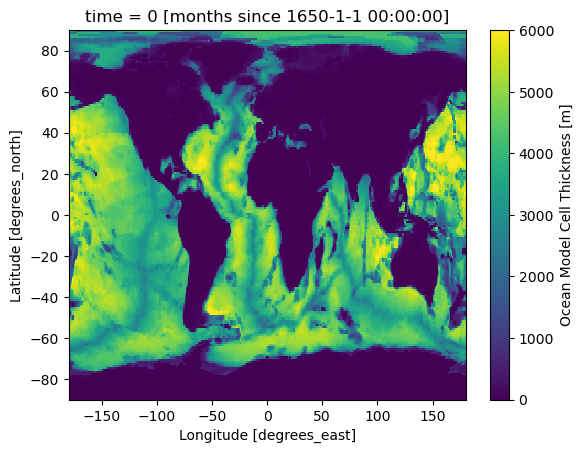

In [13]:
xr.open_zarr('/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/picontrol/IPSL-CM6A-LR/ipsl-cm6a-lr_r1i1p1f1_picontrol_thkcello_60arcmin_global_monthly_1650_1849.zarr/',
                  decode_times=False)['thkcello'].isel(time = 0).sum('olevel').plot()

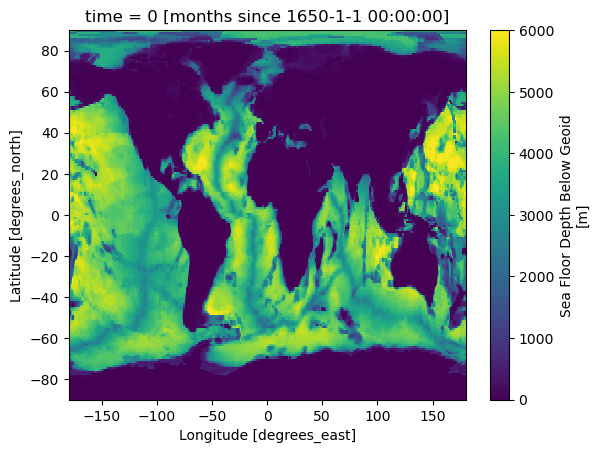

In [12]:
da.isel(time = 0).plot()

In [6]:
#Base folder where GFDL outputs are stored 
base_dir = '/g/data/vf71/fishmip_inputs/fishmip_2300/global/'

def weights_calc(input_folder):
    # Define output folder
    folder_out = (input_folder.
        replace('/global/', '/global_gridded_zarr/'))

    # Get phyc and thkcello file paths
    [phyc_fn] = glob(os.path.join(input_folder, '*_phyc_*'))
    [depth_fn] = glob(os.path.join(input_folder, '*_thkcello_*'))

    # Calculate mean over reference period
    with dask.config.set(scheduler = 'threads'):
        phyc = (uf.netcdf_to_zarr(
            phyc_fn, start_year = 1961, end_year = 1980).mean('time').
            fillna(0))
        depths = (uf.netcdf_to_zarr(
            depth_fn, start_year = 1961, end_year = 1980).mean('time').
            fillna(0))

    # Calculate weights        
    weights = phyc*depths
    weights.name = 'weights'
    weights = weights.drop_attrs()
    weights = weights.assign_attrs({
        'long_name': 'Climatological mean (1961-1980) biomass weighting'})
    
    #Save outputs
    fn_weights = os.path.join(
        folder_out, (re.sub('_[0-9]{4}\\.', '_1980.', 
                            re.sub('_[0-9]{4}_', '_1961_', os.path.basename(phyc_fn))).
            replace('.nc', '.zarr')).replace('_phyc_', '_bio-weights_'))
    weights.drop_encoding().to_zarr(
        fn_weights, consolidated = True, mode = 'w')


In [95]:
base_dir.replace('global', 'global_gridded_zarr')

'/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr'

In [92]:
# base_dir = '/g/data/vf71/fishmip_inputs/fishmip_2300/global'
# fns = glob(os.path.join(base_dir, '*/*/*expc-bot*'))
fns[0].replace('/global/', '/global_gridded_zarr/').replace('_expc-bot_', '_input-w20m_')

'/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/ssp126/IPSL-CM6A-LR/ipsl-cm6a-lr_r1i1p1f1_ssp126_input-w20m_60arcmin_global_monthly_2015_2100.nc'

In [79]:
def detrital_input_seafloor(expc_bot_file_path, benthic_habitat_depth = 20):
    '''
    Inputs:
    - folder_gridded_data (character) File path pointing to folder containing 
    zarr files for Sinking Particulate Organic Carbon Flux on Bottom 
    (`expc-bot`) from ocean model of interest
    - benthic_habitat_depth (numeric) Default is 20 (m). Vertical habitat 
    thickness (in meters) for the benthic group. This parameter represents the 
    depth above seafloor where benthic processes affecting detrital input occur

    Outputs:
    - input_w (data array) Contains detrital input near seabed needed by DBPM 
    to calculate total detritus biomass
    '''

    # Load expc-bot
    try:
        eb = xr.open_zarr(expc_bot_file_path)
        # Multiplier to transform seconds to years
        days_in_year = eb.time.dt.days_in_year*60*60*24
    except:
        #If decoding time fails, get information about time
        eb = xr.open_zarr(expc_bot_file_path, decode_times = False)
        # Getting time attributes
        da_time_atts = eb.time.attrs
        eb_org_time = eb.time
        units, reference = da_time_atts['units'].split(' since ')
        dates_df = pd.DataFrame({'origin': pd.Timestamp(reference),
                                 'offset':eb_org_time.values})
        if not isinstance(dates_df.offset, int):
            dates_df['offset'] = np.floor(dates_df.offset)
        
        if units == 'months':
            dates_df['date'] = dates_df.apply(
                lambda x: x.origin + pd.DateOffset(months = x.offset), 
                axis = 1)
        elif units == 'days':
            dates_df['date'] = dates_df.apply(
                lambda x: x.origin + pd.DateOffset(days = x.offset), 
                axis = 1)
        elif units == 'weeks':
            dates_df['date'] = dates_df.apply(
                lambda x: x.origin + pd.DateOffset(weeks = x.offset), 
                axis = 1)
        
        days_in_year = xr.DataArray(data = dates_df.apply(
            lambda x: 366 if x.date.is_leap_year else 365, axis = 1)*60*60*24, 
                                    dims = 'time', coords = {'time': eb.time})

    #Getting name of variable contained in dataset
    [var] = list(eb.keys())
   
    # Converting expc-bot from mol m-2 s-1 to gWW m-3 year-1
    input_w = eb[var]*(12.0107/0.0352)*days_in_year/benthic_habitat_depth

    # Updating metada
    input_w.name = 'input_w'
    input_w = input_w.assign_attrs(
      {'short_name': 'detrital_input_seafloor', 
       'long_name': 'Input fluxes to detritus pool near seafloor',
       'units': 'gWW m-3 yr-1'})

    return input_w

In [102]:
da = xr.open_zarr('/g/data/vf71/fishmip_inputs/fishmip_2300/global_gridded_zarr/ssp370/IPSL-CM6A-LR/ipsl-cm6a-lr_r1i1p1f1_ssp370_thkcello_60arcmin_global_monthly_2015_2100.zarr/',
                 decode_times=False)
da

<xarray.Dataset> Size: 20GB
Dimensions:   (time: 1032, olevel: 75, lat: 180, lon: 360)
Coordinates:
  * time      (time) float64 8kB 4.968e+03 4.969e+03 ... 5.998e+03 6e+03
  * olevel    (olevel) float32 300B 0.5058 1.556 2.668 ... 5.698e+03 5.902e+03
  * lat       (lat) float64 1kB 89.5 88.5 87.5 86.5 ... -86.5 -87.5 -88.5 -89.5
  * lon       (lon) float64 3kB -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
Data variables:
    thkcello  (time, olevel, lat, lon) float32 20GB dask.array<chunksize=(38, 75, 180, 360), meta=np.ndarray>

In [107]:
da.olevel.values

array([5.0576001e-01, 1.5558553e+00, 2.6676817e+00, 3.8562799e+00,
       5.1403613e+00, 6.5430336e+00, 8.0925188e+00, 9.8227501e+00,
       1.1773680e+01, 1.3991038e+01, 1.6525322e+01, 1.9429802e+01,
       2.2757616e+01, 2.6558300e+01, 3.0874561e+01, 3.5740204e+01,
       4.1180023e+01, 4.7211895e+01, 5.3850636e+01, 6.1112839e+01,
       6.9021683e+01, 7.7611160e+01, 8.6929428e+01, 9.7041313e+01,
       1.0803028e+02, 1.2000000e+02, 1.3307582e+02, 1.4740625e+02,
       1.6316446e+02, 1.8054993e+02, 1.9978996e+02, 2.2114117e+02,
       2.4489062e+02, 2.7135638e+02, 3.0088751e+02, 3.3386282e+02,
       3.7068848e+02, 4.1179385e+02, 4.5762561e+02, 5.0863989e+02,
       5.6529230e+02, 6.2802600e+02, 6.9725867e+02, 7.7336829e+02,
       8.5667896e+02, 9.4744788e+02, 1.0458542e+03, 1.1519912e+03,
       1.2658615e+03, 1.3873770e+03, 1.5163636e+03, 1.6525685e+03,
       1.7956708e+03, 1.9452955e+03, 2.1010266e+03, 2.2624216e+03,
       2.4290251e+03, 2.6003804e+03, 2.7760393e+03, 2.9555703e

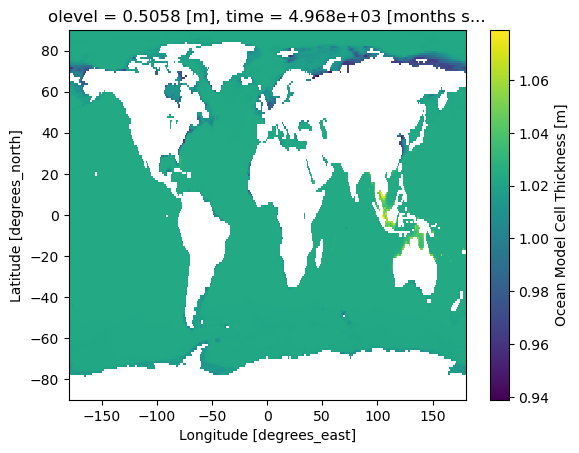

In [106]:
da['thkcello'].isel(olevel = 0, time = 0).plot()